# 01 - Data exploration (simple version)

PM2.5 forecasting, Group 1. A short, simple version of `01_eda.ipynb`.
It only uses **pandas**, **numpy** and **matplotlib**.

Steps:
1. Load the data and look at it
2. Clean PM2.5 (remove invalid values and duplicates)
3. Match each station to the nearest GEE point
4. Explore the data (summaries, plots, outliers, correlations, target)

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TARGET = "pm25"
PREDICTORS = ["AOD", "NO2", "CO", "O3", "temperature_celsius", "pressure_mb", "wind_u", "wind_v"]

# Part 1. Load and audit the data

In [2]:
pm = pd.read_csv("../data/raw/pm25.csv", parse_dates=["date"])
gee = pd.read_csv("../data/raw/gee_features_daily.csv", parse_dates=["date"])

print("pm25.csv shape:", pm.shape)
print("gee_features_daily.csv shape:", gee.shape)
pm.head()

pm25.csv shape: (88041, 5)
gee_features_daily.csv shape: (164208, 13)


,date,latitude,longitude,pm25,sensor_name
0,2016-11-21,38.788056,-0.697222,4.0,ONTINYENT
1,2016-11-21,39.456111,-0.375833,3.0,VALÈNCIA-PISTA DE SILLA
2,2016-11-21,39.480300,-0.336400,2.0,VALÈNCIA-POLITÈCNIC
3,2016-11-21,39.481100,-0.408300,5.0,VALÈNCIA - MOLÍ DEL SOL
4,2016-11-21,39.481111,-0.447222,2.0,QUART DE POBLET


In [3]:
gee.head()

,date,datetime_utc,id,lat,lon,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD
0,2016-11-21,2016-11-21 00:00:00,90,39.235833,9.115000,15.842538,994.344313,-2.613506,2.663921,NaN,NaN,NaN,0.207
1,2016-11-21,2016-11-21 00:00:00,91,39.260556,9.136389,15.842538,994.344313,-2.613506,2.663921,NaN,NaN,NaN,0.207
2,2016-11-22,2016-11-22 00:00:00,28,36.203880,-5.383710,13.119320,989.320581,1.555070,0.348089,NaN,NaN,NaN,0.277
3,2016-11-22,2016-11-22 00:00:00,40,41.426100,2.148000,15.658871,997.975164,-1.073064,0.549383,NaN,NaN,NaN,0.197
4,2016-11-22,2016-11-22 00:00:00,51,41.424066,2.185757,15.658871,997.975164,-1.073064,0.549383,NaN,NaN,NaN,0.197


## 1.1 Date range and coverage

In [4]:
print("PM2.5 dates:", pm["date"].min(), "to", pm["date"].max())
print("GEE dates:  ", gee["date"].min(), "to", gee["date"].max())
print("Number of station names:", pm["sensor_name"].nunique())
print("Number of GEE points:   ", gee["id"].nunique())

PM2.5 dates: 2016-11-21 00:00:00 to 2026-04-16 00:00:00
GEE dates:   2016-11-21 00:00:00 to 2026-04-06 00:00:00
Number of station names: 125
Number of GEE points:    100


## 1.2 Missing values

In [5]:
print("Missing values in pm25.csv:")
print(pm.isna().sum())
print()
print("Missing values in gee_features_daily.csv:")
print(gee.isna().sum())

Missing values in pm25.csv:
date           0
latitude       0
longitude      0
pm25           0
sensor_name    0
dtype: int64

Missing values in gee_features_daily.csv:
date                       0
datetime_utc               0
id                         0
lat                        0
lon                        0
temperature_celsius        0
pressure_mb                0
wind_u                     0
wind_v                     0
NO2                    19603
CO                     19603
O3                     19914
AOD                        0
dtype: int64


## 1.3 Duplicates

In [6]:
print("Full duplicate rows (pm25):", pm.duplicated().sum())
print("Same date + station name (pm25):", pm.duplicated(["date", "sensor_name"]).sum())
print("Same date + name + coordinates (pm25):", pm.duplicated(["date", "sensor_name", "latitude", "longitude"]).sum())
print("Same date + id (GEE):", gee.duplicated(["date", "id"]).sum())

Full duplicate rows (pm25): 0
Same date + station name (pm25): 1558
Same date + name + coordinates (pm25): 0
Same date + id (GEE): 0


Many rows share a date and a station name, but none share date + name + coordinates.
So some station names are used for **several places**. We fix this in 1.5.

## 1.4 PM2.5 values

In [7]:
print(pm[TARGET].describe())
print()
print("Rows with PM2.5 <= 0:  ", (pm[TARGET] <= 0).sum())
print("Rows with PM2.5 >= 500:", (pm[TARGET] >= 500).sum())

count    88041.000000
mean         8.001905
std         40.800363
min       -999.000000
25%          4.600000
50%          7.945652
75%         12.386957
max       1000.000000
Name: pm25, dtype: float64



Rows with PM2.5 <= 0:   2093
Rows with PM2.5 >= 500: 19


Values like `-999` and `1000` are not real measurements, they are codes for "no valid reading".
We remove them in Part 2.

## 1.5 Station identifiers

Some station names have more than one coordinate. If two coordinates are very close
(less than 0.01 degrees) it is the same station. If they are farther apart, it is a different station.
We build a `station_id` with this simple rule.

In [8]:
coords = pm[["sensor_name", "latitude", "longitude"]].drop_duplicates()

station_id = {}      # (name, lat, lon) -> station_id
groups = {}          # name -> list of reference coordinates

for i in range(len(coords)):
    name = coords["sensor_name"].iloc[i]
    lat = coords["latitude"].iloc[i]
    lon = coords["longitude"].iloc[i]

    if name not in groups:
        groups[name] = []

    # look for an existing group of this name that is close enough
    found = -1
    for k in range(len(groups[name])):
        ref_lat, ref_lon = groups[name][k]
        if abs(lat - ref_lat) < 0.01 and abs(lon - ref_lon) < 0.01:
            found = k
    if found == -1:
        groups[name].append((lat, lon))
        found = len(groups[name]) - 1

    station_id[(name, lat, lon)] = name + " #" + str(found + 1)

ids = []
for i in range(len(pm)):
    ids.append(station_id[(pm["sensor_name"].iloc[i], pm["latitude"].iloc[i], pm["longitude"].iloc[i])])
pm["station_id"] = ids

print("Station names:", pm["sensor_name"].nunique())
print("Station ids:  ", pm["station_id"].nunique())
print("Barcelona ids:", pm.loc[pm["sensor_name"] == "Barcelona", "station_id"].unique())

Station names: 125
Station ids:   127
Barcelona ids: <ArrowStringArray>
['Barcelona #1', 'Barcelona #2', 'Barcelona #3']
Length: 3, dtype: str


# Part 2. Cleaning

In [9]:
rows_before = len(pm)

pm = pm[pm[TARGET].notna()]
pm = pm[pm[TARGET] > 0]
pm = pm[pm[TARGET] < 500]

print("Rows before:", rows_before)
print("Rows after removing invalid PM2.5:", len(pm))
print("Removed:", rows_before - len(pm))

Rows before: 88041
Rows after removing invalid PM2.5: 85929
Removed: 2112


If a station has several readings on the same day, we keep their **average**.

In [10]:
print("Duplicate date + station_id:", pm.duplicated(["date", "station_id"]).sum())

pm = pm.groupby(["date", "station_id"], as_index=False).agg(
    sensor_name=("sensor_name", "first"),
    latitude=("latitude", "mean"),
    longitude=("longitude", "mean"),
    pm25=(TARGET, "mean"),
)
print("Rows after averaging:", len(pm))

Duplicate date + station_id: 567


Rows after averaging: 85362


# Part 3. Match stations to GEE points

Each station gets the **nearest** GEE point. If the nearest point is more than 0.25 degrees away,
the station is dropped. Then we join on date + GEE id.

In [11]:
stations = pm.groupby("station_id", as_index=False).agg(lat=("latitude", "mean"), lon=("longitude", "mean"))
points = gee[["id", "lat", "lon"]].drop_duplicates("id")

nearest_id = []
nearest_dist = []
for i in range(len(stations)):
    d = np.sqrt((points["lat"] - stations["lat"].iloc[i]) ** 2 + (points["lon"] - stations["lon"].iloc[i]) ** 2)
    nearest_id.append(points["id"].iloc[d.argmin()])
    nearest_dist.append(d.min())

stations["gee_id"] = nearest_id
stations["dist"] = nearest_dist
stations["matched"] = stations["dist"] <= 0.25

print("Stations matched:", stations["matched"].sum(), "of", len(stations))

Stations matched: 107 of 120


In [12]:
matched = stations[stations["matched"]]
df = pm.merge(matched[["station_id", "gee_id"]], on="station_id")

gee_small = gee.drop(columns=["datetime_utc", "lat", "lon"]).rename(columns={"id": "gee_id"})
df = df.merge(gee_small, on=["date", "gee_id"])

print("Final table:", df.shape)
print("Stations:", df["station_id"].nunique())
df.head()

Final table: (46912, 15)
Stations: 107


,date,station_id,sensor_name,latitude,longitude,pm25,gee_id,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD
0,2016-11-25,ALMASSORA-C. P. OCHANDO #1,ALMASSORA-C. P. OCHANDO,39.945278,-0.056389,11.666667,36,9.251236,993.626994,0.783218,-0.592618,NaN,NaN,NaN,0.0220
1,2016-11-25,ONTINYENT #1,ONTINYENT,38.788056,-0.697222,2.750000,1,6.493180,946.288660,0.230240,0.735303,NaN,NaN,NaN,0.1110
2,2016-11-30,ALCORA #1,ALCORA,40.051944,-0.189722,2.400000,35,10.044782,981.911432,-2.211047,-1.568971,NaN,NaN,NaN,0.2380
3,2016-11-30,BENICASSIM #1,BENICASSIM,40.062222,0.072778,2.600000,37,12.299584,1008.794766,-3.236886,-2.804465,NaN,NaN,NaN,0.2480
4,2016-12-02,ALBALAT DELS TARONGERS #1,ALBALAT DELS TARONGERS,39.705278,-0.336667,6.200000,102,9.225549,967.947096,0.494551,-0.294933,NaN,NaN,NaN,0.0955


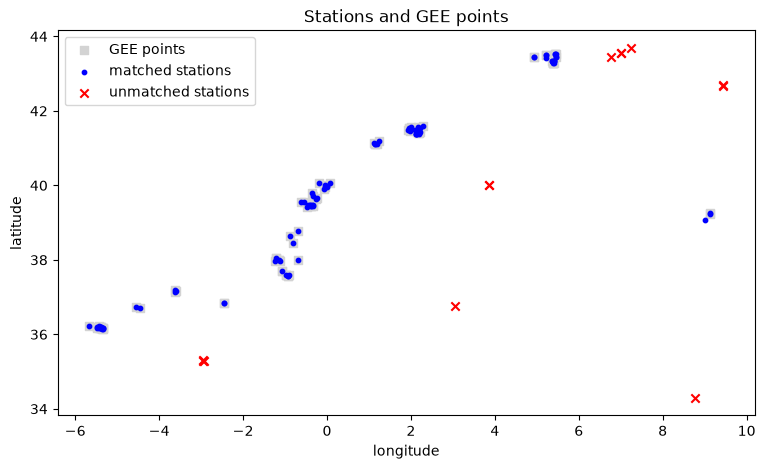

In [13]:
plt.figure(figsize=(9, 5))
plt.scatter(points["lon"], points["lat"], c="lightgrey", marker="s", label="GEE points")
plt.scatter(matched["lon"], matched["lat"], c="blue", s=10, label="matched stations")
unmatched = stations[~stations["matched"]]
plt.scatter(unmatched["lon"], unmatched["lat"], c="red", marker="x", label="unmatched stations")
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.legend()
plt.title("Stations and GEE points")
plt.show()

# Part 4. Exploration

## 4.1 Summary statistics

In [14]:
cols = [TARGET] + PREDICTORS
summary = df[cols].describe().T
summary["skewness"] = df[cols].skew()
summary["missing %"] = df[cols].isna().mean() * 100
summary.round(4)

,count,mean,std,min,25%,50%,75%,max,skewness,missing %
pm25,46912.0,9.4060,9.3912,0.0067,4.6818,7.8300,12.0000,484.9815,17.4346,0.0000
AOD,46912.0,0.1476,0.1052,0.0000,0.0790,0.1275,0.1933,5.4750,7.2710,0.0000
NO2,44505.0,0.0001,0.0000,0.0000,0.0001,0.0001,0.0001,0.0005,2.0838,5.1309
CO,44505.0,0.0317,0.0040,0.0131,0.0292,0.0315,0.0340,0.0976,1.4596,5.1309
O3,44464.0,0.1442,0.0149,0.1039,0.1343,0.1410,0.1519,0.2293,1.1634,5.2183
temperature_celsius,46912.0,18.1469,6.4375,-1.2791,12.7863,18.3108,23.7130,34.8658,-0.1021,0.0000
pressure_mb,46912.0,994.1129,16.5416,930.3171,988.2117,997.4758,1005.2583,1033.6622,-1.0946,0.0000
wind_u,46912.0,0.3959,2.4818,-11.0987,-0.9171,0.2470,1.7216,9.6617,-0.1731,0.0000
wind_v,46912.0,-0.2342,1.4829,-10.8600,-0.8018,0.0266,0.6755,8.4864,-1.3526,0.0000


In [15]:
df["month"] = df["date"].dt.month
df["year"] = df["date"].dt.year

season_of_month = {12: "winter", 1: "winter", 2: "winter",
                   3: "spring", 4: "spring", 5: "spring",
                   6: "summer", 7: "summer", 8: "summer",
                   9: "autumn", 10: "autumn", 11: "autumn"}
df["season"] = df["month"].map(season_of_month)

print(df["year"].value_counts().sort_index())

year
2016      111
2017     2116
2018      252
2019     1772
2020     3251
2021     4938
2022     5117
2023     6022
2024    11251
2025    10080
2026     2002
Name: count, dtype: int64


## 4.2 Histograms

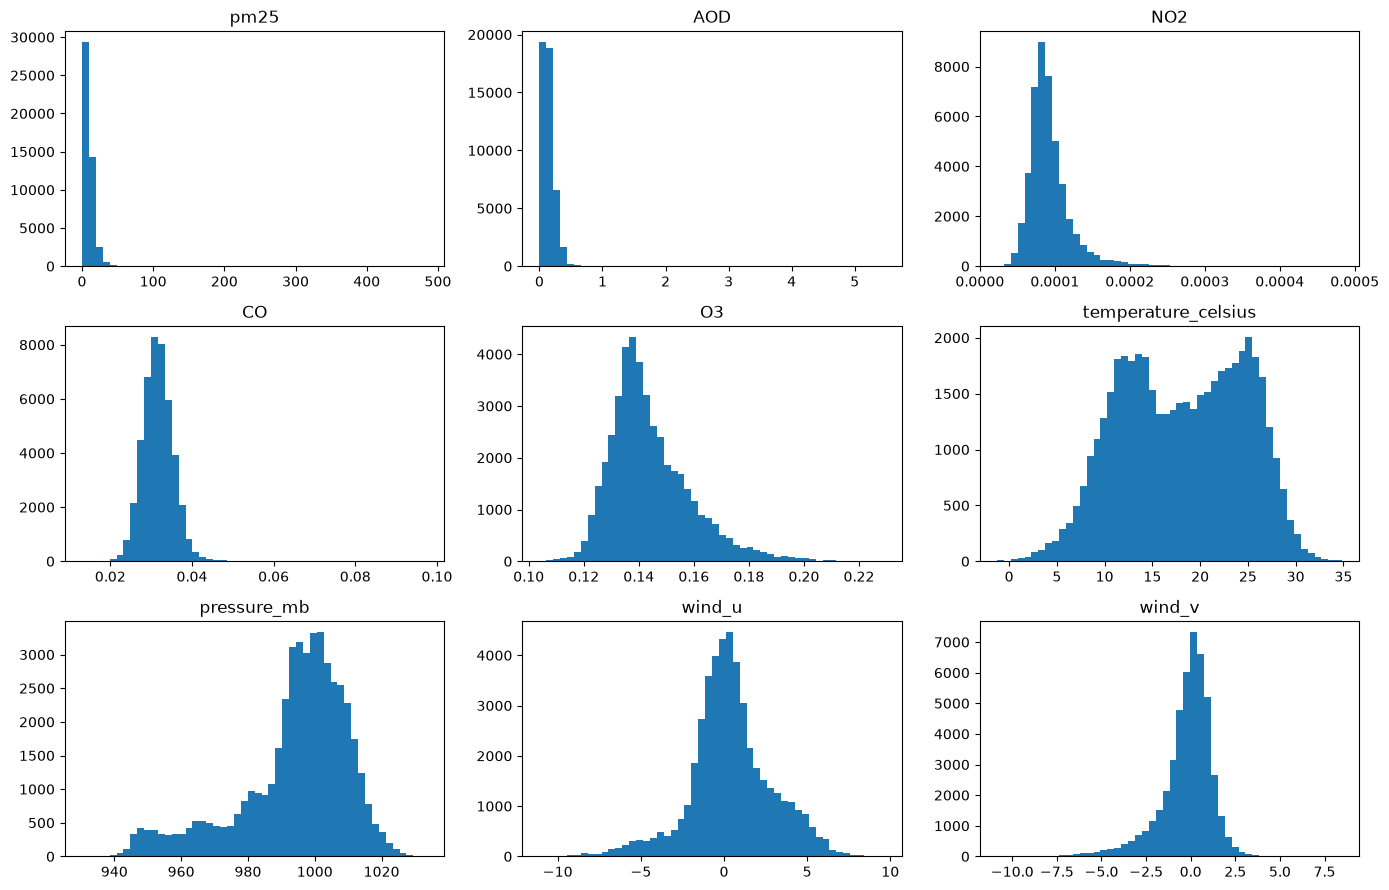

In [16]:
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
axes = axes.flatten()
for i in range(len(cols)):
    axes[i].hist(df[cols[i]].dropna(), bins=50)
    axes[i].set_title(cols[i])
plt.tight_layout()
plt.show()

## 4.3 Boxplots

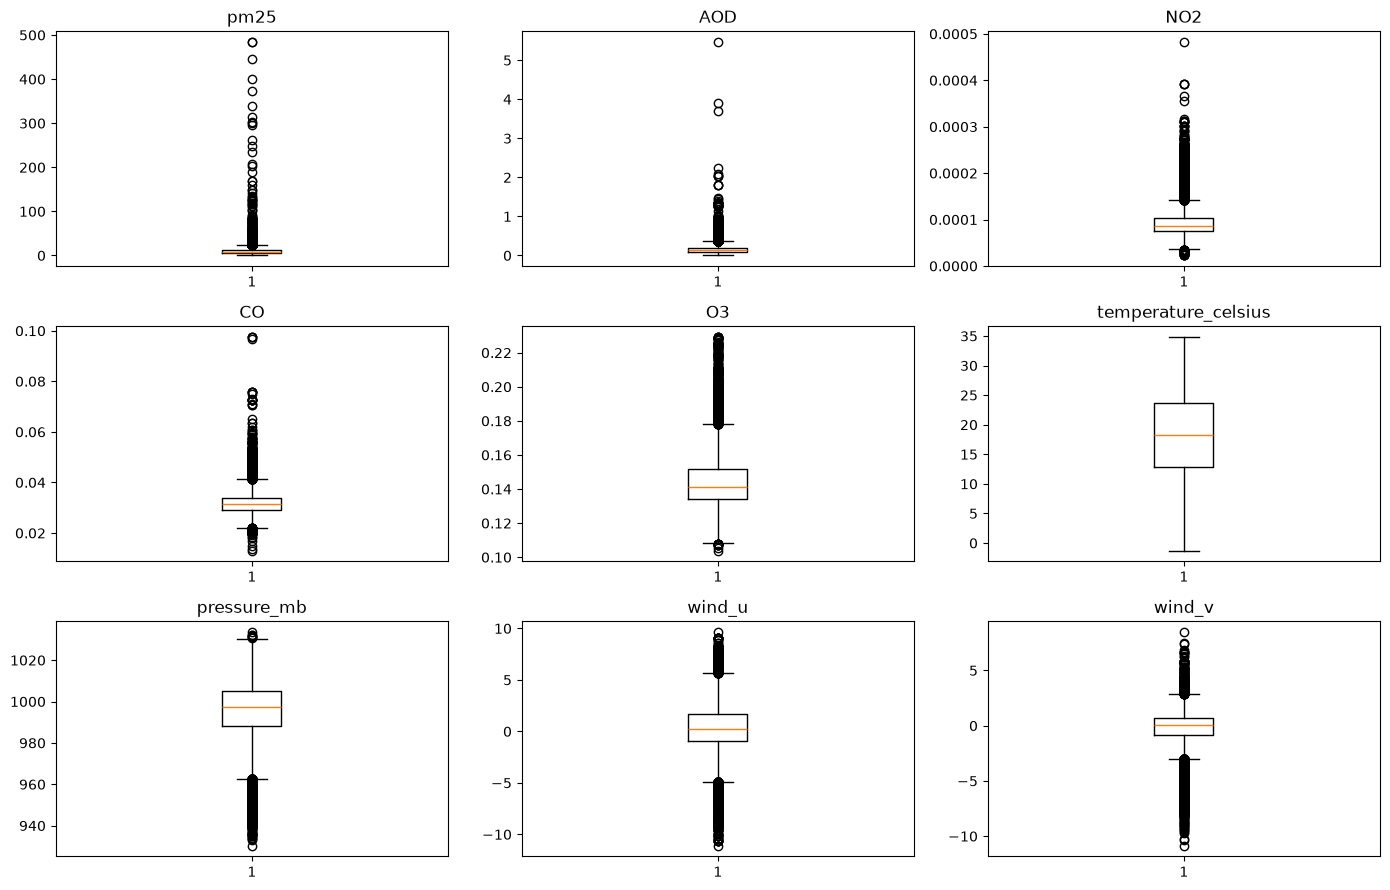

In [17]:
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
axes = axes.flatten()
for i in range(len(cols)):
    axes[i].boxplot(df[cols[i]].dropna())
    axes[i].set_title(cols[i])
plt.tight_layout()
plt.show()

## 4.4 PM2.5 by season and by month

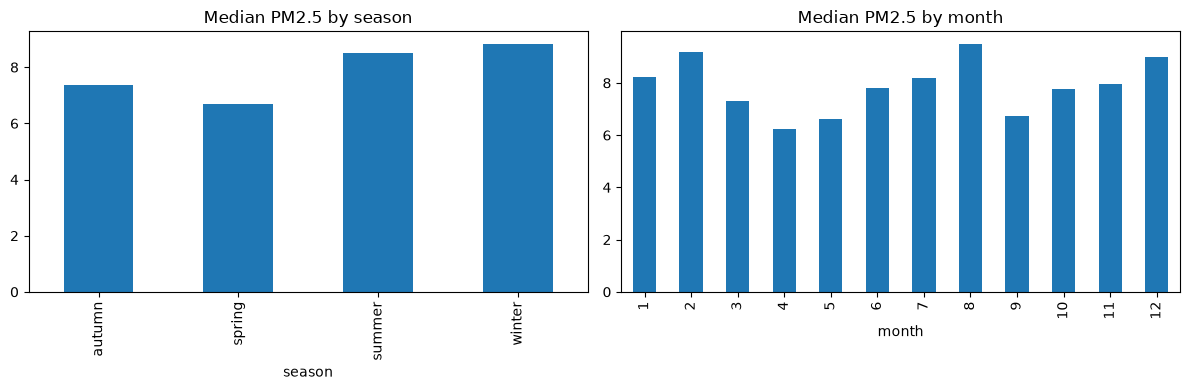

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df.groupby("season")[TARGET].median().plot(kind="bar", ax=axes[0])
axes[0].set_title("Median PM2.5 by season")

df.groupby("month")[TARGET].median().plot(kind="bar", ax=axes[1])
axes[1].set_title("Median PM2.5 by month")

plt.tight_layout()
plt.show()

## 4.5 Outliers (IQR rule)

In [19]:
for c in cols:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n = ((df[c] < low) | (df[c] > high)).sum()
    print(c, ": outliers =", n)

pm25 : outliers = 1915
AOD : outliers = 1259
NO2 : outliers = 2343
CO : outliers = 688
O3 : outliers = 1484
temperature_celsius : outliers = 0
pressure_mb : outliers = 3316
wind_u : outliers = 2367
wind_v : outliers = 2706


Outliers are **only inspected, not removed**. High PM2.5 values can be real pollution episodes.

## 4.6 Correlations

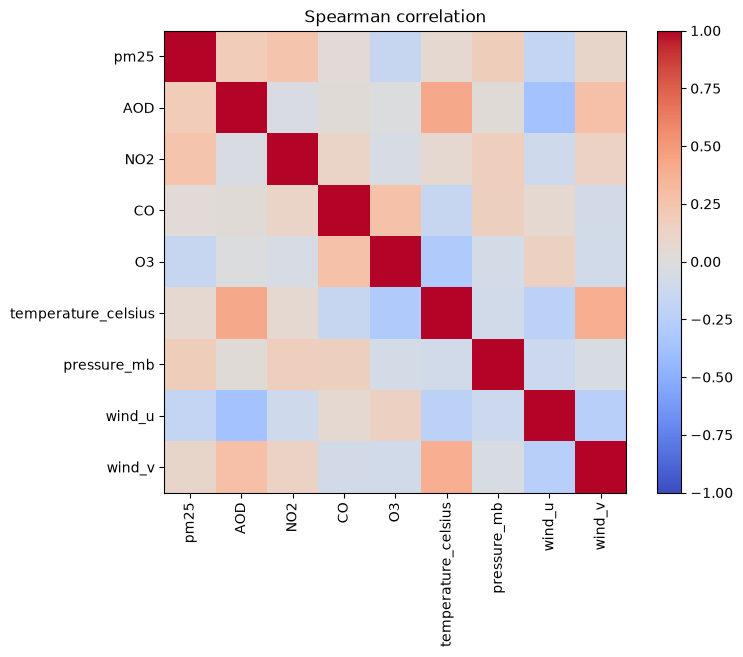

Correlation with PM2.5:
wind_u                -0.173
O3                    -0.153
CO                     0.038
temperature_celsius    0.062
wind_v                 0.096
pressure_mb            0.172
AOD                    0.181
NO2                    0.249
pm25                   1.000
Name: pm25, dtype: float64


In [20]:
corr = df[cols].corr(method="spearman")

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(cols)), cols, rotation=90)
plt.yticks(range(len(cols)), cols)
plt.title("Spearman correlation")
plt.show()

print("Correlation with PM2.5:")
print(corr[TARGET].sort_values().round(3))

All correlations with PM2.5 are weak, so no single variable predicts PM2.5 well.

## 4.7 PM2.5 vs AOD

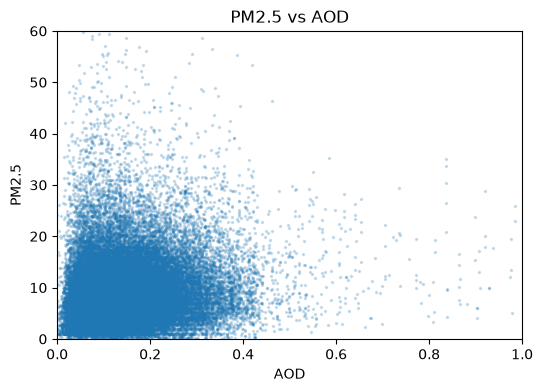

In [21]:
plt.figure(figsize=(6, 4))
plt.scatter(df["AOD"], df[TARGET], s=2, alpha=0.2)
plt.xlim(0, 1)
plt.ylim(0, 60)
plt.xlabel("AOD")
plt.ylabel("PM2.5")
plt.title("PM2.5 vs AOD")
plt.show()

## 4.8 Target distribution

mean:   9.41
median: 7.83
skewness: 17.43
share of days > 25: 3.0 %


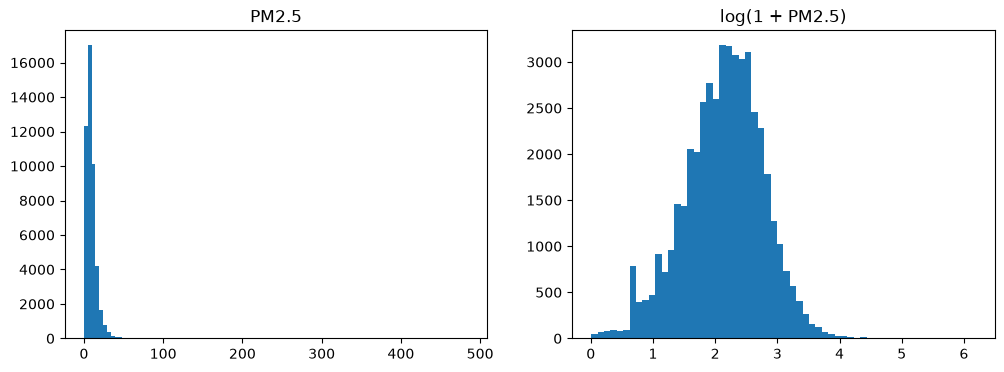

In [22]:
print("mean:  ", round(df[TARGET].mean(), 2))
print("median:", round(df[TARGET].median(), 2))
print("skewness:", round(df[TARGET].skew(), 2))
print("share of days > 25:", round((df[TARGET] > 25).mean() * 100, 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df[TARGET], bins=100)
axes[0].set_title("PM2.5")
axes[1].hist(np.log1p(df[TARGET]), bins=60)
axes[1].set_title("log(1 + PM2.5)")
plt.show()

**Conclusion.** PM2.5 is strongly right-skewed: most days are clean and a few are very polluted.
- Report both **MAE** and **RMSE** (RMSE is pulled up by the rare extreme days).
- `log(1 + PM2.5)` is much more symmetric and can be tested as a transformed target.

## Save the cleaned table

In [23]:
df.to_csv("../data/processed/data_cleaned_simple.csv", index=False)
print("saved", df.shape)

saved (46912, 18)
